# Use Case 4: MySQL Reporting and Integration

**Objective.** Store, query and present analytical results from the database.

| Task | What is done |
|---|---|
| 1 | Create three summary tables and fill them from Python with the MySQL Connector |
| 2 | Write SQL for crimes per year, top 5 crime types with percentages, and arrests per year |
| 3 | Create the views `vw_crime_yearly` and `vw_crime_by_category` |
| 4 | Read the views into pandas with `pd.read_sql` |
| 5 | Plot the SQL results with Matplotlib and Seaborn |

**Input.** The `crime` table from Notebook 01.

**Database.** With MySQL configured in `.env`, this notebook uses `mysql.connector`. Without MySQL it uses Python's built-in `sqlite3` with the same SQL and the same code. Only the placeholder symbol differs (`%s` for MySQL, `?` for SQLite), and it is picked automatically.

In [1]:
import warnings

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display

from db_config import get_dbapi_connection, save_fig, write_report

warnings.filterwarnings("ignore", message="pandas only supports SQLAlchemy")
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 200)
FOLDER = "use_case_4"
sections = []

conn, backend, ph = get_dbapi_connection()
cur = conn.cursor()
cur.execute("SELECT COUNT(*) FROM crime")
print(f"Backend: {backend}. Rows in the crime table: {cur.fetchone()[0]}")

Using SQLite database chicago_crime_analysis.db (MySQL is not configured or not running).
Backend: sqlite. Rows in the crime table: 498


## Task 1: Design and populate summary tables

Three small tables hold ready-made results, so reports do not have to scan every crime row.

| Table | Content |
|---|---|
| `summary_crime_yearly` | crimes per year |
| `summary_crime_by_category` | crimes and percentage per crime type |
| `summary_arrest_yearly` | crimes, arrests and arrest rate per year |

The tables are created here. They are filled after the SQL queries of Task 2, because the queries produce the data.

In [2]:
ddl = [
    "DROP TABLE IF EXISTS summary_crime_yearly",
    "DROP TABLE IF EXISTS summary_crime_by_category",
    "DROP TABLE IF EXISTS summary_arrest_yearly",
    '''CREATE TABLE summary_crime_yearly (
           crime_year  INT NOT NULL PRIMARY KEY,
           crime_count INT NOT NULL)''',
    '''CREATE TABLE summary_crime_by_category (
           primary_type VARCHAR(64) NOT NULL PRIMARY KEY,
           crime_count  INT NOT NULL,
           percentage   DECIMAL(5,2) NOT NULL)''',
    '''CREATE TABLE summary_arrest_yearly (
           crime_year      INT NOT NULL PRIMARY KEY,
           total_crimes    INT NOT NULL,
           arrest_count    INT NOT NULL,
           arrest_rate_pct DECIMAL(5,2) NOT NULL)''',
]
for statement in ddl:
    cur.execute(statement)
conn.commit()
print("Summary tables created.")

Summary tables created.


## Task 2: MySQL queries

Each query reads the `crime` table directly.

* **Crime count per year:** `GROUP BY crime_year`.
* **Top 5 crime types and percentages:** the percentage is the type's count divided by the total number of crimes, found with a sub-query.
* **Arrest count per year:** `arrest` is 1 or 0, so a conditional `SUM` counts the arrests.

In [3]:
Q_YEARLY = '''
SELECT crime_year, COUNT(*) AS crime_count
FROM crime
GROUP BY crime_year
ORDER BY crime_year'''

Q_CATEGORY = '''
SELECT primary_type,
       COUNT(*) AS crime_count,
       ROUND(100.0 * COUNT(*) / (SELECT COUNT(*) FROM crime), 2) AS percentage
FROM crime
GROUP BY primary_type
ORDER BY crime_count DESC, primary_type'''

Q_TOP5 = Q_CATEGORY + " LIMIT 5"

Q_ARREST = '''
SELECT crime_year,
       COUNT(*) AS total_crimes,
       SUM(CASE WHEN arrest = 1 THEN 1 ELSE 0 END) AS arrest_count
FROM crime
GROUP BY crime_year
ORDER BY crime_year'''


def run(sql):
    cur.execute(sql)
    columns = [d[0] for d in cur.description]
    return pd.DataFrame(cur.fetchall(), columns=columns)


yearly_q = run(Q_YEARLY)
top5_q = run(Q_TOP5)
arrest_q = run(Q_ARREST)
arrest_q["arrest_count"] = arrest_q["arrest_count"].astype(int)
print("Crime count per year"); display(yearly_q)
print("Top 5 crime types and percentages"); display(top5_q)
print("Arrest count per year"); display(arrest_q)

Crime count per year


,crime_year,crime_count
0,2012,2
1,2013,1
2,2014,1
3,2015,4
4,2016,490


Top 5 crime types and percentages


,primary_type,crime_count,percentage
0,THEFT,105,21.08
1,BATTERY,85,17.07
2,CRIMINAL DAMAGE,49,9.84
3,OTHER OFFENSE,39,7.83
4,DECEPTIVE PRACTICE,38,7.63


Arrest count per year


,crime_year,total_crimes,arrest_count
0,2012,2,2
1,2013,1,1
2,2014,1,0
3,2015,4,2
4,2016,490,119


### Task 1 (continued): load the summary tables

The results are inserted with `executemany` through the connector. Values are passed as parameters, not pasted into the SQL text.

In [4]:
all_categories = run(Q_CATEGORY)

cur.executemany(f"INSERT INTO summary_crime_yearly (crime_year, crime_count) VALUES ({ph}, {ph})",
                [(int(r.crime_year), int(r.crime_count)) for r in yearly_q.itertuples()])
cur.executemany(f"INSERT INTO summary_crime_by_category (primary_type, crime_count, percentage) VALUES ({ph}, {ph}, {ph})",
                [(r.primary_type, int(r.crime_count), float(r.percentage)) for r in all_categories.itertuples()])
cur.executemany(f"INSERT INTO summary_arrest_yearly (crime_year, total_crimes, arrest_count, arrest_rate_pct) VALUES ({ph}, {ph}, {ph}, {ph})",
                [(int(r.crime_year), int(r.total_crimes), int(r.arrest_count),
                  round(100 * int(r.arrest_count) / int(r.total_crimes), 2)) for r in arrest_q.itertuples()])
conn.commit()

for table in ["summary_crime_yearly", "summary_crime_by_category", "summary_arrest_yearly"]:
    cur.execute(f"SELECT COUNT(*) FROM {table}")
    print(f"{table}: {cur.fetchone()[0]} rows")

summary_crime_yearly: 5 rows
summary_crime_by_category: 23 rows
summary_arrest_yearly: 5 rows


## Task 3: Database views

A view is a saved query that behaves like a table and always reflects the current data.

* `vw_crime_yearly`: crimes, arrests and arrest rate for each year.
* `vw_crime_by_category`: crimes and percentage for each crime type.

`DROP VIEW IF EXISTS` followed by `CREATE VIEW` works in both MySQL and SQLite, so the notebook can be re-run.

In [5]:
cur.execute("DROP VIEW IF EXISTS vw_crime_yearly")
cur.execute('''
CREATE VIEW vw_crime_yearly AS
SELECT crime_year,
       COUNT(*) AS total_crimes,
       SUM(CASE WHEN arrest = 1 THEN 1 ELSE 0 END) AS arrest_count,
       ROUND(100.0 * SUM(CASE WHEN arrest = 1 THEN 1 ELSE 0 END) / COUNT(*), 2) AS arrest_rate_pct
FROM crime
GROUP BY crime_year''')

cur.execute("DROP VIEW IF EXISTS vw_crime_by_category")
cur.execute('''
CREATE VIEW vw_crime_by_category AS
SELECT primary_type,
       COUNT(*) AS crime_count,
       ROUND(100.0 * COUNT(*) / (SELECT COUNT(*) FROM crime), 2) AS percentage
FROM crime
GROUP BY primary_type''')
conn.commit()
print("Views created: vw_crime_yearly, vw_crime_by_category")

Views created: vw_crime_yearly, vw_crime_by_category


## Task 4: Pandas integration

The views are read into DataFrames with `pd.read_sql`. MySQL returns `DECIMAL` values as Python `Decimal`, so numeric columns are converted to numbers.

In [6]:
vw_yearly = pd.read_sql("SELECT * FROM vw_crime_yearly ORDER BY crime_year", conn)
vw_category = pd.read_sql("SELECT * FROM vw_crime_by_category ORDER BY crime_count DESC, primary_type", conn)

for frame in (vw_yearly, vw_category):
    for col in frame.columns.drop(["primary_type"], errors="ignore"):
        frame[col] = pd.to_numeric(frame[col])

print("vw_crime_yearly"); display(vw_yearly)
print("vw_crime_by_category (first 10 rows)"); display(vw_category.head(10))

vw_crime_yearly


,crime_year,total_crimes,arrest_count,arrest_rate_pct
0,2012,2,2,100.00
1,2013,1,1,100.00
2,2014,1,0,0.00
3,2015,4,2,50.00
4,2016,490,119,24.29


vw_crime_by_category (first 10 rows)


,primary_type,crime_count,percentage
0,THEFT,105,21.08
1,BATTERY,85,17.07
2,CRIMINAL DAMAGE,49,9.84
3,OTHER OFFENSE,39,7.83
4,DECEPTIVE PRACTICE,38,7.63
5,ASSAULT,35,7.03
6,NARCOTICS,32,6.43
7,ROBBERY,30,6.02
8,CRIMINAL TRESPASS,17,3.41
9,MOTOR VEHICLE THEFT,16,3.21


### Check: view results equal the Task 2 queries

In [7]:
same_yearly = vw_yearly["total_crimes"].tolist() == yearly_q["crime_count"].tolist()
same_arrests = vw_yearly["arrest_count"].tolist() == arrest_q["arrest_count"].tolist()
same_category = vw_category["crime_count"].tolist() == all_categories["crime_count"].tolist()
print("Yearly counts match:", same_yearly, "| Arrest counts match:", same_arrests, "| Category counts match:", same_category)
assert same_yearly and same_arrests and same_category

Yearly counts match: True | Arrest counts match: True | Category counts match: True


## Task 5: Visualization from MySQL data

Five charts are drawn only from data read out of the database with SQL. Matplotlib and Seaborn do the drawing.

| Chart | Data source |
|---|---|
| 1. Crimes and arrests per year | view `vw_crime_yearly` |
| 2. Top crime types | view `vw_crime_by_category` |
| 3. Monthly crime frequency | SQL `GROUP BY crime_year, crime_month` |
| 4. Top 10 community areas | SQL join with `ref_community` |
| 5. Crimes by police district | SQL join with `ref_district` |

Charts 4 and 5 need the names of communities and districts. They are stored in two small reference tables, `ref_community` and `ref_district`, which are loaded from the raw CSV files first.

In [8]:
import pandas as pd
from db_config import RAW_DIR

cur.execute("DROP TABLE IF EXISTS ref_community")
cur.execute("DROP TABLE IF EXISTS ref_district")
cur.execute("CREATE TABLE ref_community (community_code INT NOT NULL PRIMARY KEY, community_name VARCHAR(64) NOT NULL)")
cur.execute("CREATE TABLE ref_district (district_code INT NOT NULL PRIMARY KEY, district_name VARCHAR(64) NOT NULL)")

comm = pd.read_csv(RAW_DIR / "chicago_city_community.csv")
dist = pd.read_csv(RAW_DIR / "chicago_district_ps_info.csv")
dist["district_code"] = pd.to_numeric(dist["DISTRICT_CODE"], errors="coerce")
dist = dist.dropna(subset=["district_code"])

cur.executemany(f"INSERT INTO ref_community VALUES ({ph}, {ph})",
                [(int(r.community_code), str(r.community_name).strip().upper()) for r in comm.itertuples()])
cur.executemany(f"INSERT INTO ref_district VALUES ({ph}, {ph})",
                [(int(r.district_code), str(r.DISTRICT_NAME).strip().upper()) for r in dist.itertuples()])
conn.commit()
for table in ["ref_community", "ref_district"]:
    cur.execute(f"SELECT COUNT(*) FROM {table}")
    print(f"{table}: {cur.fetchone()[0]} rows")

BLUE, RED = "#2b6c8f", "#c0392b"
interpretations = {}   # chart name -> interpretation text

ref_community: 77 rows
ref_district: 22 rows


### Chart 1: crimes and arrests per year (Matplotlib and Seaborn, data from view `vw_crime_yearly`)

Grouped bars compare the number of crimes with the number of arrests in each year. The arrest rate is written under each year.

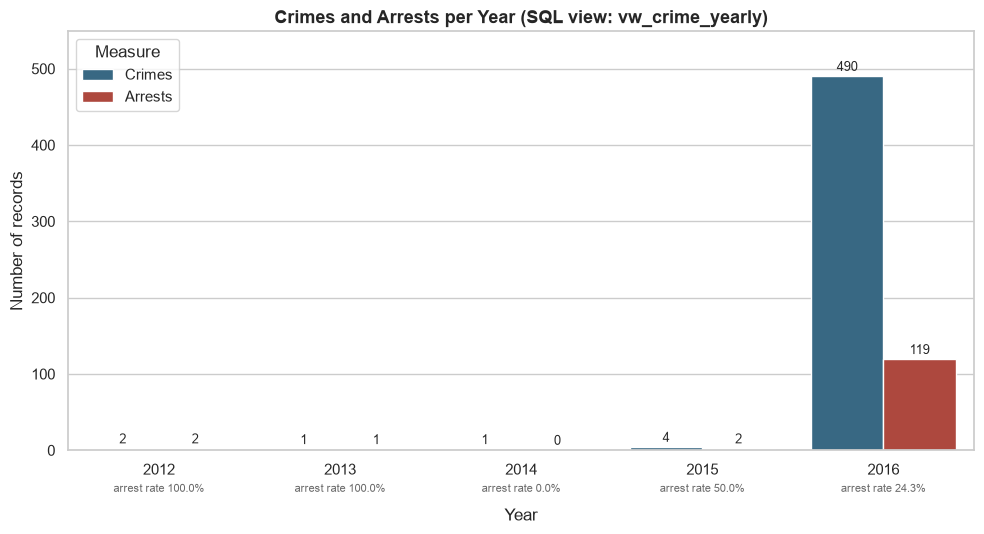

**Interpretation.** 2016 has the most crimes (490 of 498) and 119 arrests (24.3%). Other years have only 1 to 4 records, so their arrest rates (0% to 100%) are not reliable. The sample covers few dates outside the peak year.

In [9]:
long = vw_yearly.melt(id_vars="crime_year", value_vars=["total_crimes", "arrest_count"], var_name="measure", value_name="records")
long["measure"] = long["measure"].map({"total_crimes": "Crimes", "arrest_count": "Arrests"})

fig, ax = plt.subplots(figsize=(10, 5.5))
sns.barplot(data=long, x="crime_year", y="records", hue="measure", palette=[BLUE, RED], ax=ax)
for container in ax.containers:
    ax.bar_label(container, fmt="%d", padding=2, fontsize=9)
for i, r in enumerate(vw_yearly.itertuples()):
    ax.text(i, -0.08, f"arrest rate {r.arrest_rate_pct:.1f}%", transform=ax.get_xaxis_transform(),
            ha="center", va="top", fontsize=8, color="dimgray")
ax.set_title("Crimes and Arrests per Year (SQL view: vw_crime_yearly)", fontsize=13, fontweight="bold")
ax.set_xlabel("Year", labelpad=22)
ax.set_ylabel("Number of records")
ax.set_ylim(0, long["records"].max() * 1.12)
ax.legend(title="Measure")
fig.tight_layout()
save_fig(fig, FOLDER, "01_crimes_and_arrests_by_year.png")
plt.show()

peak = vw_yearly.loc[vw_yearly["total_crimes"].idxmax()]
text_c1 = (f"{int(peak.crime_year)} has the most crimes ({int(peak.total_crimes)} of {int(vw_yearly['total_crimes'].sum())}) and "
           f"{int(peak.arrest_count)} arrests ({peak.arrest_rate_pct:.1f}%). Other years have only "
           f"{int(vw_yearly['total_crimes'].min())} to {int(vw_yearly[vw_yearly['crime_year'] != peak.crime_year]['total_crimes'].max())} records, "
           "so their arrest rates (0% to 100%) are not reliable. The sample covers few dates outside the peak year.")
interpretations["Chart 1: Crimes and arrests per year"] = text_c1
display(Markdown("**Interpretation.** " + text_c1))

### Chart 2: top crime types and their share (Seaborn, data from view `vw_crime_by_category`)

The 10 largest crime types in the view. Each bar shows the percentage of all crimes and, in brackets, the number of crimes.

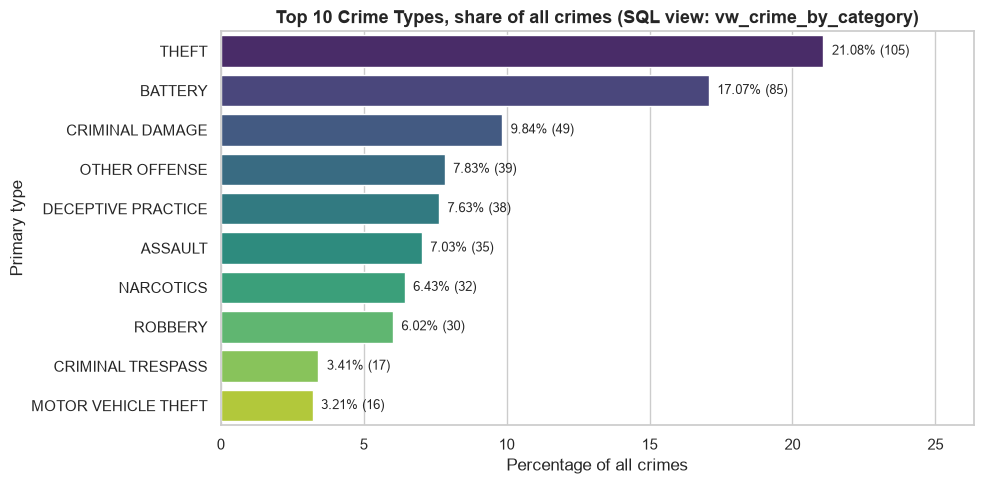

**Interpretation.** THEFT is the largest type with 105 crimes (21.08%), followed by BATTERY (17.07%). The top 5 types cover 63.45% of all crimes and the top 10 cover 89.55%. The view holds 23 crime types in total.

In [10]:
top10 = vw_category.head(10)
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=top10, y="primary_type", x="percentage", hue="primary_type", legend=False, palette="viridis", ax=ax)
for i, row in enumerate(top10.itertuples()):
    ax.text(row.percentage + 0.3, i, f"{row.percentage}% ({row.crime_count})", va="center", fontsize=9)
ax.set_title("Top 10 Crime Types, share of all crimes (SQL view: vw_crime_by_category)", fontsize=13, fontweight="bold")
ax.set_xlabel("Percentage of all crimes")
ax.set_ylabel("Primary type")
ax.set_xlim(0, top10["percentage"].max() * 1.25)
fig.tight_layout()
save_fig(fig, FOLDER, "02_top10_crime_types.png")
plt.show()

top5_share = vw_category.head(5)["percentage"].sum()
text_c2 = (f"{top10.iloc[0].primary_type} is the largest type with {int(top10.iloc[0].crime_count)} crimes ({top10.iloc[0].percentage}%), "
           f"followed by {top10.iloc[1].primary_type} ({top10.iloc[1].percentage}%). The top 5 types cover {top5_share:.2f}% of all crimes "
           f"and the top 10 cover {top10['percentage'].sum():.2f}%. The view holds {len(vw_category)} crime types in total.")
interpretations["Chart 2: Top crime types"] = text_c2
display(Markdown("**Interpretation.** " + text_c2))

### Chart 3: monthly crime frequency (Matplotlib, SQL `GROUP BY crime_year, crime_month`)

One point for each year-month that has records. Months without records are not on the axis, so the spacing is not to time scale.

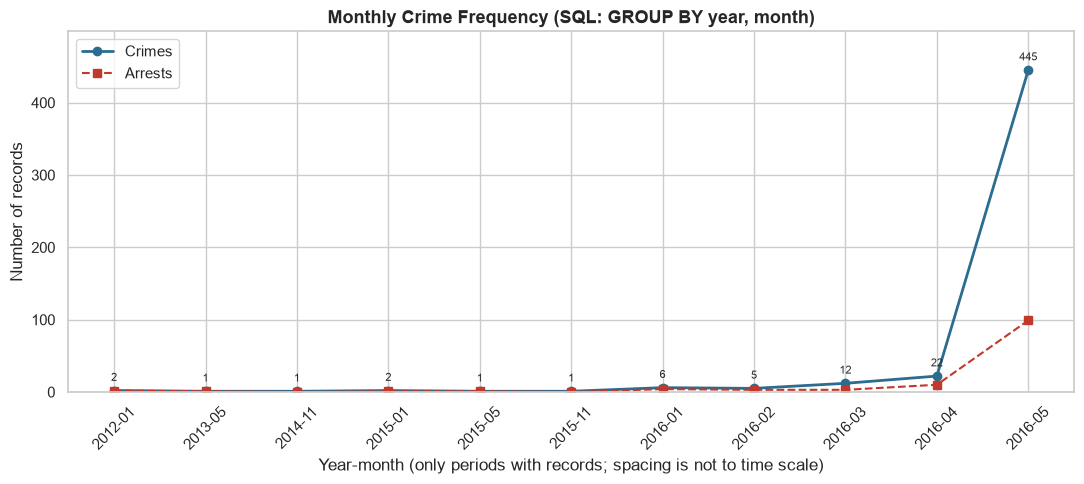

**Interpretation.** 11 year-month periods have records. The busiest is 2016-05 with 445 crimes (89.4% of all crimes). The second highest has 22. A single month holding most records shows that the sample covers specific dates, not a full year, so this is not a seasonal pattern.

In [11]:
monthly = run('''
SELECT crime_year, crime_month,
       COUNT(*) AS crimes,
       SUM(CASE WHEN arrest = 1 THEN 1 ELSE 0 END) AS arrests
FROM crime
GROUP BY crime_year, crime_month
ORDER BY crime_year, crime_month''')
monthly[["crimes", "arrests"]] = monthly[["crimes", "arrests"]].apply(pd.to_numeric)
monthly["period"] = [f"{int(y)}-{int(m):02d}" for y, m in zip(monthly["crime_year"], monthly["crime_month"])]

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(monthly["period"], monthly["crimes"], marker="o", color=BLUE, linewidth=2, label="Crimes")
ax.plot(monthly["period"], monthly["arrests"], marker="s", color=RED, linewidth=1.5, linestyle="--", label="Arrests")
for x, y in zip(monthly["period"], monthly["crimes"]):
    ax.annotate(str(y), (x, y), textcoords="offset points", xytext=(0, 7), ha="center", fontsize=8)
ax.set_title("Monthly Crime Frequency (SQL: GROUP BY year, month)", fontsize=13, fontweight="bold")
ax.set_xlabel("Year-month (only periods with records; spacing is not to time scale)")
ax.set_ylabel("Number of records")
ax.set_ylim(0, monthly["crimes"].max() * 1.12)
ax.tick_params(axis="x", rotation=45)
ax.legend()
fig.tight_layout()
save_fig(fig, FOLDER, "03_monthly_crime_frequency.png")
plt.show()

busiest = monthly.loc[monthly["crimes"].idxmax()]
text_c3 = (f"{len(monthly)} year-month periods have records. The busiest is {busiest.period} with {int(busiest.crimes)} crimes "
           f"({busiest.crimes / monthly['crimes'].sum() * 100:.1f}% of all crimes). The second highest has "
           f"{int(monthly['crimes'].nlargest(2).iloc[-1])}. A single month holding most records shows that the sample covers specific dates, "
           "not a full year, so this is not a seasonal pattern.")
interpretations["Chart 3: Monthly crime frequency"] = text_c3
display(Markdown("**Interpretation.** " + text_c3))

### Chart 4: top 10 community areas (Seaborn, SQL join with `ref_community`)

The query joins `crime` with `ref_community` to get the community name, counts crimes per area and calculates each area's share of all crimes.

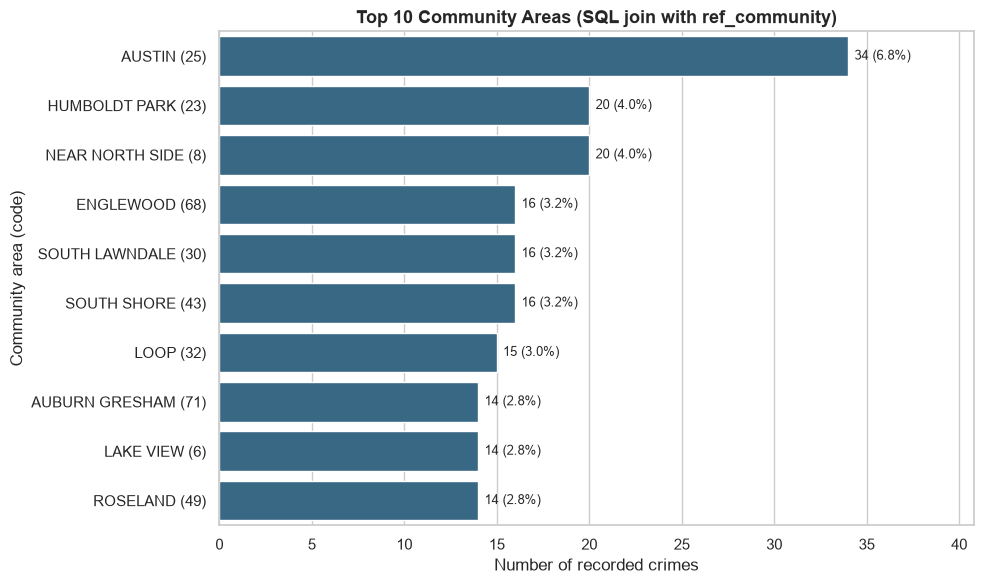

**Interpretation.** Austin has the most crimes: 34 (6.8%). The top 10 areas together cover 35.9% of all crimes. These are raw counts, not adjusted for population.

In [12]:
Q_COMMUNITY = '''
SELECT c.community_code, r.community_name,
       COUNT(*) AS crimes,
       ROUND(100.0 * COUNT(*) / (SELECT COUNT(*) FROM crime), 2) AS pct_of_total
FROM crime c
JOIN ref_community r ON r.community_code = c.community_code
GROUP BY c.community_code, r.community_name
ORDER BY crimes DESC, r.community_name
LIMIT 10'''
areas = run(Q_COMMUNITY)
areas[["crimes", "pct_of_total"]] = areas[["crimes", "pct_of_total"]].apply(pd.to_numeric)
areas["label"] = [f"{n} ({c})" for n, c in zip(areas["community_name"], areas["community_code"])]

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(data=areas, y="label", x="crimes", color=BLUE, ax=ax)
for i, r in enumerate(areas.itertuples()):
    ax.text(r.crimes + areas["crimes"].max() * 0.01, i, f"{r.crimes} ({r.pct_of_total:.1f}%)", va="center", fontsize=9)
ax.set_title("Top 10 Community Areas (SQL join with ref_community)", fontsize=13, fontweight="bold")
ax.set_xlabel("Number of recorded crimes")
ax.set_ylabel("Community area (code)")
ax.set_xlim(0, areas["crimes"].max() * 1.2)
fig.tight_layout()
save_fig(fig, FOLDER, "04_top10_community_areas.png")
plt.show()

text_c4 = (f"{areas.iloc[0].community_name.title()} has the most crimes: {int(areas.iloc[0].crimes)} ({areas.iloc[0].pct_of_total:.1f}%). "
           f"The top 10 areas together cover {areas['pct_of_total'].sum():.1f}% of all crimes. These are raw counts, not adjusted for population.")
interpretations["Chart 4: Top 10 community areas"] = text_c4
display(Markdown("**Interpretation.** " + text_c4))

### Chart 5: crimes by police district (Seaborn, SQL join with `ref_district`)

Crimes per police district, from the most to the least. The dashed line is the median district.

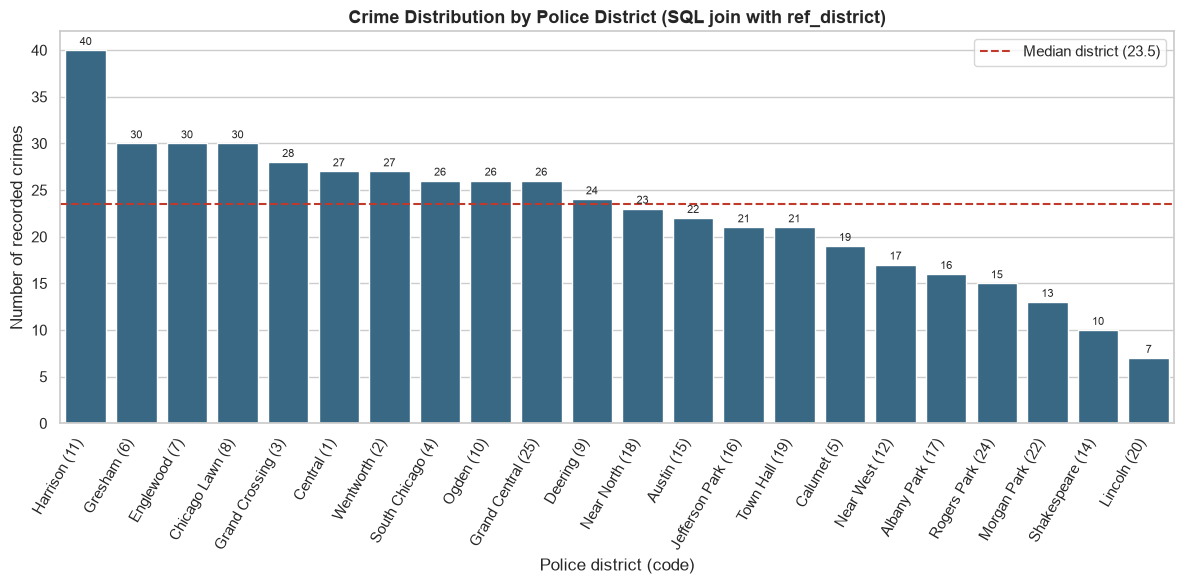

**Interpretation.** 22 police districts have crimes. Harrison (district 11) has the most with 40 crimes, and Lincoln has the fewest with 7. The median district has 23.5. Raw counts, not adjusted for district size or population.

In [13]:
Q_DISTRICT = '''
SELECT c.district_code, COALESCE(r.district_name, 'UNKNOWN') AS district_name, COUNT(*) AS crimes
FROM crime c
LEFT JOIN ref_district r ON r.district_code = c.district_code
GROUP BY c.district_code, r.district_name
ORDER BY crimes DESC, c.district_code'''
districts = run(Q_DISTRICT)
districts["crimes"] = pd.to_numeric(districts["crimes"])
districts["label"] = [f"{n.title()} ({c})" for n, c in zip(districts["district_name"], districts["district_code"])]

fig, ax = plt.subplots(figsize=(12, 6))
sns.barplot(data=districts, x="label", y="crimes", color=BLUE, ax=ax)
ax.axhline(districts["crimes"].median(), color=RED, linestyle="--", label=f"Median district ({districts['crimes'].median():g})")
ax.bar_label(ax.containers[0], fmt="%d", padding=2, fontsize=8)
ax.set_title("Crime Distribution by Police District (SQL join with ref_district)", fontsize=13, fontweight="bold")
ax.set_xlabel("Police district (code)")
ax.set_ylabel("Number of recorded crimes")
ax.tick_params(axis="x", rotation=60)
for tick in ax.get_xticklabels():
    tick.set_horizontalalignment("right")
ax.legend()
fig.tight_layout()
save_fig(fig, FOLDER, "05_crimes_by_police_district.png")
plt.show()

text_c5 = (f"{len(districts)} police districts have crimes. {districts.iloc[0].district_name.title()} (district {int(districts.iloc[0].district_code)}) "
           f"has the most with {int(districts.iloc[0].crimes)} crimes, and {districts.iloc[-1].district_name.title()} has the fewest with {int(districts.iloc[-1].crimes)}. "
           f"The median district has {districts['crimes'].median():g}. Raw counts, not adjusted for district size or population.")
interpretations["Chart 5: Crimes by police district"] = text_c5
display(Markdown("**Interpretation.** " + text_c5))

## Results

The text is generated from the query results and saved to `data/reports/use_case_4/use_case_4_interpretations.md`.

In [14]:
total = int(vw_yearly["total_crimes"].sum())
overall_rate = vw_yearly["arrest_count"].sum() / total * 100

sections = [
    ("Task 1: Summary tables", "Created and filled summary_crime_yearly "
     f"({len(yearly_q)} rows), summary_crime_by_category ({len(all_categories)} rows) and summary_arrest_yearly ({len(arrest_q)} rows) "
     f"through the {backend} connection."),
    ("Task 2: Queries", "Crime count per year: " + "; ".join(f"{int(r.crime_year)}: {int(r.crime_count)}" for r in yearly_q.itertuples()) + ". "
     "Top 5 crime types: " + "; ".join(f"{r.primary_type} {r.crime_count} ({r.percentage}%)" for r in top5_q.itertuples()) + ". "
     "Arrests per year: " + "; ".join(f"{int(r.crime_year)}: {r.arrest_count} of {r.total_crimes}" for r in arrest_q.itertuples()) + "."),
    ("Task 3: Views", "vw_crime_yearly and vw_crime_by_category were created and return the same numbers as the Task 2 queries."),
    ("Task 4: Pandas integration", f"Both views were read with pd.read_sql: vw_crime_yearly has {len(vw_yearly)} rows and vw_crime_by_category has {len(vw_category)} rows."),
    ("Task 5: Overall", f"{total} crimes in total, {int(vw_yearly['arrest_count'].sum())} with an arrest ({overall_rate:.2f}%)."),
] + [(f"Task 5, {name}", text) for name, text in interpretations.items()]
write_report(FOLDER, "use_case_4_interpretations.md", "Use Case 4 interpretations", sections)
for heading, body in sections[4:]:
    display(Markdown(f"**{heading}**\n\n{body}"))
conn.close()

**Task 5: Overall**

498 crimes in total, 124 with an arrest (24.90%).

**Task 5, Chart 1: Crimes and arrests per year**

2016 has the most crimes (490 of 498) and 119 arrests (24.3%). Other years have only 1 to 4 records, so their arrest rates (0% to 100%) are not reliable. The sample covers few dates outside the peak year.

**Task 5, Chart 2: Top crime types**

THEFT is the largest type with 105 crimes (21.08%), followed by BATTERY (17.07%). The top 5 types cover 63.45% of all crimes and the top 10 cover 89.55%. The view holds 23 crime types in total.

**Task 5, Chart 3: Monthly crime frequency**

11 year-month periods have records. The busiest is 2016-05 with 445 crimes (89.4% of all crimes). The second highest has 22. A single month holding most records shows that the sample covers specific dates, not a full year, so this is not a seasonal pattern.

**Task 5, Chart 4: Top 10 community areas**

Austin has the most crimes: 34 (6.8%). The top 10 areas together cover 35.9% of all crimes. These are raw counts, not adjusted for population.

**Task 5, Chart 5: Crimes by police district**

22 police districts have crimes. Harrison (district 11) has the most with 40 crimes, and Lincoln has the fewest with 7. The median district has 23.5. Raw counts, not adjusted for district size or population.